# HDD 05 - Telemetry regime discovery
**VS Code / local Jupyter.** Run top to bottom after Notebook 04's final completion cell.

This implements the **Discover** stage: fit an embedding transform and HDBSCAN on training representations, assign April/May windows with the frozen model, describe the regimes, and check support, temporal persistence and resampling stability.

No model is trained here, and the June test and failure labels remain closed. We have not reviewed your completed Notebook 04 outputs. Passing its file checks establishes a usable artifact, not scientific quality. This notebook can legitimately conclude that the representations do not yet support reliable regimes.

**Important:** clusters describe similar recorded behaviour. Neither a cluster nor HDBSCAN noise automatically means healthy, failing or anomalous. A stable, damaged drive can create a dense cluster. IDs such as R0 are arbitrary experiment-local names.

A laptop-sized drive-balanced, temporally thinned training subset is used for fitting HDBSCAN. The frozen predictor assigns all working windows afterward. The fitting subset and indices are saved; this sampling choice must be disclosed in the research report.


## 1. Dependencies
Use the same VS Code Python kernel as Notebooks 03/04. This uses the third-party **hdbscan** package, not `sklearn.cluster.HDBSCAN`, because its frozen approximate predictor is needed. If installation says loaded packages require restarting, restart the kernel and continue below.


In [1]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "pyarrow>=16" "hdbscan>=0.8.40,<0.9" joblib matplotlib tqdm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Paths and upstream integrity
The default component path matches your uploaded Notebook 03. Change it only if the repository moved. Match SSL_ID to Notebook 04 if you renamed the encoder experiment. New clustering settings require a new REGIME_ID.


In [2]:
from pathlib import Path
import json, hashlib, warnings, time, platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, hdbscan
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from hdbscan.prediction import approximate_predict
from hdbscan.validity import validity_index
from tqdm.auto import tqdm

COMPONENT_ROOT=Path(r"D:/SLIIT/Y4S1/RP/Research/J26-DS-342-/01_component_1_behavioral_drift_genai")
RUN_ID='single_model_q1q2_2021_v1'
SSL_ID='masked_transformer_v1_seed42'
REGIME_ID='hdbscan_regimes_v1'
SEED=42

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()

SSL_OUT=COMPONENT_ROOT/'results'/RUN_ID/SSL_ID
ENCODER_COMPLETE=SSL_OUT/'encoder_complete.json'
if not ENCODER_COMPLETE.is_file():
    raise FileNotFoundError(f'Complete Notebook 04 first, or correct COMPONENT_ROOT/SSL_ID. Expected: {ENCODER_COMPLETE.resolve()}')
encoder_record=json.loads(ENCODER_COMPLETE.read_text())
assert encoder_record['run_id']==RUN_ID and encoder_record['ssl_id']==SSL_ID
assert encoder_record['failure_labels_used'] is False and encoder_record['sealed_test_opened'] is False
for relative,digest in encoder_record['representation_files'].items():
    assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed representation: {relative}'
checkpoint=COMPONENT_ROOT/'models/trained'/RUN_ID/SSL_ID/'best_encoder.pt'
assert sha256(checkpoint)==encoder_record['checkpoint_sha256'], 'Encoder checkpoint changed.'
# Hashing does not load a PyTorch model; no torch dependency is required here.
DATA_COMPLETE=COMPONENT_ROOT/'experiments'/RUN_ID/'dataset_complete.json'
data_record=json.loads(DATA_COMPLETE.read_text())
assert sha256(DATA_COMPLETE)==encoder_record['settings']['dataset_complete_sha256']
for relative,digest in data_record['working_hashes'].items():
    assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed source window: {relative}'
FEATURES=encoder_record['settings']['features']
EMBED_ROOT=COMPONENT_ROOT/'data/features'/RUN_ID/SSL_ID
OUT=COMPONENT_ROOT/'results'/RUN_ID/REGIME_ID
MODEL_DIR=COMPONENT_ROOT/'models/trained'/RUN_ID/REGIME_ID
for folder in [OUT,MODEL_DIR]: folder.mkdir(parents=True,exist_ok=True)
print('Component:',COMPONENT_ROOT.resolve())
print('Encoder:',SSL_ID,'| Regime experiment:',REGIME_ID)


Component: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai
Encoder: masked_transformer_v1_seed42 | Regime experiment: hdbscan_regimes_v1


c:\Users\IMAKA\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Load aligned embeddings and original window summaries
Raw SMART values are used only to describe clusters and inspect confounding, never as failure labels. The per-window summaries remain aligned with encoder metadata. Missing and invalid windows were already excluded under Notebook 02's strict policy.


In [3]:
embeddings,metadata,reconstruction,raw_summaries={},{},{},{}
for split in ['train','calibration','development']:
    folder=EMBED_ROOT/split
    with np.load(folder/'representations.npz') as data:
        embeddings[split]=data['embeddings'].astype(np.float64)
        reconstruction[split]=data['reconstruction_score']
    metadata[split]=pd.read_parquet(folder/'metadata.parquet').reset_index(drop=True)
    source=COMPONENT_ROOT/'data/features'/RUN_ID/split
    original_meta=pd.read_parquet(source/'metadata.parquet').reset_index(drop=True)
    pd.testing.assert_frame_equal(metadata[split],original_meta)
    with np.load(source/'windows_raw.npz') as data:
        raw=data['X'].astype(np.float64)
    assert len(raw)==len(embeddings[split])==len(metadata[split])
    assert embeddings[split].ndim==2 and np.isfinite(embeddings[split]).all()
    summaries={}
    for j,feature in enumerate(FEATURES):
        summaries[feature+'_last']=raw[:,-1,j]
        summaries[feature+'_median']=np.median(raw[:,:,j],axis=1)
        summaries[feature+'_std']=raw[:,:,j].std(axis=1)
        summaries[feature+'_net_change']=raw[:,-1,j]-raw[:,0,j]
    raw_summaries[split]=pd.DataFrame(summaries)
    print(split,embeddings[split].shape,'| drives:',metadata[split]['serial_number'].nunique())
del raw
for a in metadata:
    for b in metadata:
        if a!=b: assert set(metadata[a]['serial_number']).isdisjoint(metadata[b]['serial_number'])
print('No June or failure-label data loaded.')


train (42578, 32) | drives: 700
calibration (4410, 32) | drives: 147
development (4642, 32) | drives: 150
No June or failure-label data loaded.


## 4. Declare the clustering protocol and create a fitting subset
Take the earliest eligible endpoint and then endpoints at least 10 days apart per training drive, capped at 8 per drive and 6,000 total. Windows still overlap, so this reduces duplication without making samples independent. If the global cap is reached, round-robin selection balances drives. Full training windows are assigned after fitting.

Standardise latent dimensions and use unwhitened PCA capped at 8 dimensions, both fitted on this training subset only. This cap is a declared first experiment, not proof that discarded dimensions are irrelevant. Record retained variance and later compare no-PCA/other dimensions as ablations. The fitted coordinate system is shared across every HDBSCAN candidate and held-out split.

Use sampled DBCV on one fixed subset of at most 1,500 fitting points to limit pairwise memory. This is a sampled estimate, not full-data DBCV. Silhouette is secondary and also sampled. Selection uses training data only; April/May are reported after selection.


In [4]:
SETTINGS={
    'seed':SEED,'fit_spacing_days':10,'fit_max_per_drive':8,'fit_max_total':6000,
    'pca_cap':8,'dbcv_sample_max':1500,'silhouette_sample_max':1000,
    'min_cluster_sizes':[30,60,120],'min_samples_values':[5,15],
    'minimum_assigned_fraction':.50,'minimum_unique_drives_per_regime':5,
    'stability_seeds':[43,44,45],'stability_drive_fraction':.8,'stability_anchor_max':5000,
    'provisional_ari_target':.70,'shuffle_repeats':20,
    'encoder_complete_sha256':sha256(ENCODER_COMPLETE),
    'selection_rule':'training-only: >=2 clusters, assigned fraction >=.5, every cluster >=5 fitting drives, finite sampled DBCV; rank by DBCV then coverage',
}
settings_path=MODEL_DIR/'settings.json'
if settings_path.exists() and json.loads(settings_path.read_text())!=SETTINGS:
    raise ValueError('Existing settings differ. Use a new REGIME_ID.')
settings_path.write_text(json.dumps(SETTINGS,indent=2))

def fitting_indices(meta,spacing,max_per_drive,max_total):
    groups=[]
    for serial,part in meta.groupby('serial_number',sort=True):
        accepted=[]; previous=None
        for index,row in part.sort_values('end_date').iterrows():
            endpoint=pd.Timestamp(row['end_date'])
            if previous is None or (endpoint-previous).days>=spacing:
                accepted.append(int(index)); previous=endpoint
            if len(accepted)>=max_per_drive: break
        groups.append(accepted)
    # Seeded drive order avoids always privileging alphabetically first serials at the cap.
    rng=np.random.default_rng(SEED); rng.shuffle(groups)
    indices=[]
    for rank in range(max_per_drive):
        for group in groups:
            if rank<len(group): indices.append(group[rank])
            if len(indices)>=max_total: return np.array(sorted(indices),dtype=int)
    return np.array(sorted(indices),dtype=int)

fit_indices=fitting_indices(metadata['train'],SETTINGS['fit_spacing_days'],SETTINGS['fit_max_per_drive'],SETTINGS['fit_max_total'])
if len(fit_indices)<150: raise ValueError('Too few thinned training windows for this declared grid. Inspect coverage or define a new smaller experiment explicitly.')
fit_meta=metadata['train'].iloc[fit_indices].reset_index(drop=True)
fit_meta.assign(original_window_index=fit_indices).to_csv(OUT/'clustering_fit_windows.csv',index=False)
scaler=StandardScaler().fit(embeddings['train'][fit_indices])
scaled_fit=scaler.transform(embeddings['train'][fit_indices])
if np.linalg.matrix_rank(scaled_fit)<2:
    raise ValueError('Embeddings are collapsed or effectively constant; inspect/retrain the encoder before clustering.')
n_components=min(SETTINGS['pca_cap'],scaled_fit.shape[1],len(scaled_fit)-1)
pca=PCA(n_components=n_components,svd_solver='full').fit(scaled_fit)
Z={split:np.ascontiguousarray(pca.transform(scaler.transform(value)),dtype=np.float64) for split,value in embeddings.items()}
Z_fit=Z['train'][fit_indices]
assert np.isfinite(Z_fit).all()
variance=pd.DataFrame({'component':np.arange(1,n_components+1),'explained_variance_ratio':pca.explained_variance_ratio_})
variance.to_csv(OUT/'pca_variance.csv',index=False)
print('Fitting windows:',len(fit_indices),'| fitting drives:',fit_meta['serial_number'].nunique())
print('PCA dimensions:',n_components,'| retained variance:',round(float(pca.explained_variance_ratio_.sum()),4))
metric_indices=np.sort(np.random.default_rng(SEED).choice(len(Z_fit),min(SETTINGS['dbcv_sample_max'],len(Z_fit)),replace=False))


Fitting windows: 4885 | fitting drives: 700
PCA dimensions: 8 | retained variance: 0.996


## 5. Fit and assess the training-only HDBSCAN grid
This initial grid has six candidates. Fitting drives, not repeated windows alone, must support every cluster. Noise is -1. `prediction_data=True` stores the information needed for later assignments without reclustering held-out windows.

A candidate can fail to produce multiple clusters or meaningful validation scores. Keep those negative results. If no candidate meets the predeclared support rules, the notebook saves a diagnostic and stops; do not force a fixed number of clusters just to move forward.


In [5]:
def make_clusterer(min_cluster_size,min_samples):
    return hdbscan.HDBSCAN(min_cluster_size=int(min_cluster_size),min_samples=int(min_samples),
        metric='euclidean',cluster_selection_method='eom',allow_single_cluster=False,
        prediction_data=True,core_dist_n_jobs=1,approx_min_span_tree=False)

def safe_predict(clusterer,values):
    if not np.any(clusterer.labels_>=0):
        return np.full(len(values),-1,dtype=int),np.zeros(len(values),dtype=float)
    labels,strengths=approximate_predict(clusterer,np.ascontiguousarray(values,dtype=np.float64))
    assert np.isfinite(strengths).all()
    return labels.astype(int),strengths

candidates=[]; fitted={}
for mcs in SETTINGS['min_cluster_sizes']:
    for ms in SETTINGS['min_samples_values']:
        name=f'mcs{mcs}_ms{ms}'; started=time.perf_counter()
        clusterer=make_clusterer(mcs,ms).fit(Z_fit)
        labels=clusterer.labels_; clusters=sorted(set(labels)-{-1})
        support=pd.DataFrame({'label':labels,'serial_number':fit_meta['serial_number']})
        per_cluster=support.loc[support['label'].ge(0)].groupby('label')['serial_number'].nunique()
        row={'candidate':name,'min_cluster_size':mcs,'min_samples':ms,'clusters':len(clusters),
            'assigned_fraction':float((labels>=0).mean()),
            'minimum_fitting_drives_per_cluster':int(per_cluster.min()) if len(per_cluster) else 0,
            'dbcv_sampled':None,'silhouette_sampled':None,'metric_warning':''}
        sampled_labels=labels[metric_indices]
        valid_labels=sorted(set(sampled_labels)-{-1})
        if len(valid_labels)>=2 and all(np.sum(sampled_labels==k)>=3 for k in valid_labels):
            # Remap sampled labels: tiny rare clusters absent from the sample should not create gaps.
            remapped=np.full(len(sampled_labels),-1,dtype=int)
            for new,old in enumerate(valid_labels): remapped[sampled_labels==old]=new
            try:
                with warnings.catch_warnings(record=True) as notices:
                    value=float(validity_index(Z_fit[metric_indices],remapped,metric='euclidean'))
                if np.isfinite(value): row['dbcv_sampled']=value
                row['metric_warning']='; '.join(str(w.message) for w in notices)
            except (ValueError,ZeroDivisionError,FloatingPointError) as exc:
                row['metric_warning']=f'DBCV unavailable: {exc}'
            keep=sampled_labels>=0
            if keep.sum()>len(valid_labels):
                try: row['silhouette_sampled']=float(silhouette_score(Z_fit[metric_indices][keep],sampled_labels[keep],sample_size=min(SETTINGS['silhouette_sample_max'],int(keep.sum())),random_state=SEED))
                except ValueError as exc: row['metric_warning']+='; silhouette unavailable: '+str(exc)
        else: row['metric_warning']='Sample has fewer than two usable clusters or fewer than three points in a cluster.'
        row['eligible']=bool(len(clusters)>=2 and row['assigned_fraction']>=SETTINGS['minimum_assigned_fraction']
            and row['minimum_fitting_drives_per_cluster']>=SETTINGS['minimum_unique_drives_per_regime']
            and row['dbcv_sampled'] is not None)
        row['fit_seconds']=time.perf_counter()-started
        candidates.append(row); fitted[name]=clusterer
        print(name,'clusters:',len(clusters),'assigned:',round(row['assigned_fraction'],3),'eligible:',row['eligible'])
candidate_table=pd.DataFrame(candidates)
candidate_table.to_csv(OUT/'candidate_metrics.csv',index=False)
display(candidate_table)
eligible=candidate_table.loc[candidate_table['eligible']].sort_values(['dbcv_sampled','assigned_fraction'],ascending=False)
if eligible.empty:
    (OUT/'no_supported_regimes.json').write_text(json.dumps({'status':'no_candidate_meets_declared_rules','settings':SETTINGS,
        'next_action':'Inspect embeddings, PCA variance, drive support and encoder results. Record a new protocol before changing the grid.'},indent=2))
    raise RuntimeError('No supported candidate. Diagnostics saved. This is a valid negative result; do not open June or force clusters.')
best=eligible.iloc[0]
clusterer=fitted[best['candidate']]
print('Selected using training data only:',best['candidate'])


mcs30_ms5 clusters: 2 assigned: 0.997 eligible: True
mcs30_ms15 clusters: 2 assigned: 0.865 eligible: True
mcs60_ms5 clusters: 2 assigned: 0.895 eligible: True
mcs60_ms15 clusters: 2 assigned: 0.865 eligible: True
mcs120_ms5 clusters: 3 assigned: 0.446 eligible: False
mcs120_ms15 clusters: 3 assigned: 0.397 eligible: False


,candidate,min_cluster_size,min_samples,clusters,assigned_fraction,minimum_fitting_drives_per_cluster,dbcv_sampled,silhouette_sampled,metric_warning,eligible,fit_seconds
0,mcs30_ms5,30,5,2,0.996725,6,0.633990,0.578924,,True,0.911569
1,mcs30_ms15,30,15,2,0.865097,17,0.412651,0.270431,,True,0.708014
2,mcs60_ms5,60,5,2,0.894780,20,0.343917,0.251480,,True,0.702369
3,mcs60_ms15,60,15,2,0.865097,17,0.412651,0.270431,,True,0.691276
4,mcs120_ms5,120,5,3,0.446469,50,-0.042211,0.350635,,False,0.414454
5,mcs120_ms15,120,15,3,0.396725,62,-0.001194,0.419059,,False,0.322762


Selected using training data only: mcs30_ms5


## 6. Assign all working windows using the frozen predictor
All three splits use the same approximate prediction rule. Training fitting labels are retained separately in `clustering_fit_windows.csv`; approximate predictions on fitting points can differ near boundaries. Prediction holds the fitted hierarchy fixed and cannot discover a new cluster in April/May. A noise assignment may indicate unsupported behaviour, not a confirmed fault.

`membership_strength` is HDBSCAN's assignment strength; it is not a health confidence or failure probability. Do not compare arbitrary numeric cluster IDs between experiments.


In [6]:
assignments={}
fit_export=fit_meta.assign(original_window_index=fit_indices,fit_cluster_label=clusterer.labels_)
fit_export.to_csv(OUT/'clustering_fit_windows.csv',index=False)
for split,values in Z.items():
    labels,strengths=safe_predict(clusterer,values)
    table=metadata[split].copy()
    table['regime_label']=labels
    table['regime_id']=[f'R{k}' if k>=0 else 'noise' for k in labels]
    table['membership_strength']=strengths
    table['reconstruction_score']=reconstruction[split]
    table.to_csv(OUT/f'{split}_regime_assignments.csv',index=False)
    assignments[split]=table
summary=pd.DataFrame([{'split':split,'windows':len(table),'drives':table['serial_number'].nunique(),
    'assigned_percent':100*table['regime_label'].ge(0).mean(),'noise_percent':100*table['regime_label'].eq(-1).mean(),
    'regimes_present':table.loc[table['regime_label'].ge(0),'regime_label'].nunique()} for split,table in assignments.items()])
summary.to_csv(OUT/'assignment_summary.csv',index=False)
display(summary.round(3))


,split,windows,drives,assigned_percent,noise_percent,regimes_present
0,train,42578,700,99.671,0.329,2
1,calibration,4410,147,98.639,1.361,2
2,development,4642,150,99.332,0.668,1


## 7. Describe training regimes and inspect confounding
Report raw SMART window statistics, distinct drives, reconstruction errors and membership strength. Values such as SMART 9 remain raw units until vendor encoding is validated. Persistent nonzero error counters do not become harmless because they form a cluster.

A regime strongly separated by SMART 9 level might describe drive age rather than a useful operating state. Compare age and temperature levels against their changes/variability before giving it a semantic name. April/May profiles are descriptive held-out diagnostics; they do not change the selected model here.


In [7]:
profile_rows=[]
for split,table in assignments.items():
    joined=pd.concat([table.reset_index(drop=True),raw_summaries[split].reset_index(drop=True)],axis=1)
    profiles=joined.groupby('regime_id')[raw_summaries[split].columns.tolist()].median()
    profiles.to_csv(OUT/f'{split}_regime_raw_medians.csv')
    for regime,part in joined.groupby('regime_id'):
        drive_counts=part['serial_number'].value_counts()
        profile_rows.append({'split':split,'regime_id':regime,'windows':len(part),
            'unique_drives':part['serial_number'].nunique(),'largest_drive_window_share':float(drive_counts.max()/len(part)),
            'median_membership_strength':part['membership_strength'].median(),
            'median_reconstruction_score':part['reconstruction_score'].median()})
profiles=pd.DataFrame(profile_rows)
profiles.to_csv(OUT/'regime_support_profiles.csv',index=False)
display(profiles.loc[profiles['split'].eq('train')])
display(pd.read_csv(OUT/'train_regime_raw_medians.csv'))


,split,regime_id,windows,unique_drives,largest_drive_window_share,median_membership_strength,median_reconstruction_score
0,train,R0,347,6,0.175793,1.0,0.004748
1,train,R1,42091,693,0.001449,1.0,0.002375
2,train,noise,140,3,0.435714,0.0,0.026521


,regime_id,smart_5_raw_last,smart_5_raw_median,smart_5_raw_std,smart_5_raw_net_change,smart_9_raw_last,smart_9_raw_median,smart_9_raw_std,smart_9_raw_net_change,smart_194_raw_last,...,smart_194_raw_std,smart_194_raw_net_change,smart_197_raw_last,smart_197_raw_median,smart_197_raw_std,smart_197_raw_net_change,smart_198_raw_last,smart_198_raw_median,smart_198_raw_std,smart_198_raw_net_change
0,R0,24.0,24.0,0.0,0.0,11209.0,10861.00,207.587347,699.0,27.0,...,0.933928,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,R1,0.0,0.0,0.0,0.0,8304.0,7957.00,207.832197,696.0,28.0,...,1.085766,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,noise,320.0,312.0,0.0,0.0,11026.5,10682.75,207.663488,694.5,31.0,...,1.396220,0.0,16.0,16.0,0.0,0.0,16.0,16.0,0.0,0.0


## 8. Temporal persistence against a within-drive shuffled control
Only pairs of consecutive scoring dates are compared, within the same serial. Report both same-label rate including noise and same-regime rate when both endpoints are assigned. Noise runs must not be interpreted as a stable operating regime.

Shuffle labels within each drive, preserving that drive's label frequencies, and compare to 20 null repeats. This is a diagnostic, not a formal significance test: overlapping windows naturally create smooth labels. If each drive stays in only one cluster, shuffling cannot change its persistence. Such a result does not demonstrate learned temporal regime switching.


In [8]:
def temporal_rates(table):
    frame=table.sort_values(['serial_number','end_date']).copy()
    same_drive=frame['serial_number'].eq(frame['serial_number'].shift())
    consecutive=frame['end_date'].diff().dt.days.eq(1)&same_drive
    previous=frame['regime_label'].shift()
    both_assigned=consecutive & frame['regime_label'].ge(0) & previous.ge(0)
    equal=frame['regime_label'].eq(previous)
    return {'consecutive_pairs':int(consecutive.sum()),'both_assigned_pairs':int(both_assigned.sum()),
        'same_label_including_noise':float(equal[consecutive].mean()) if consecutive.any() else np.nan,
        'same_regime_assigned_pairs':float(equal[both_assigned].mean()) if both_assigned.any() else np.nan}

def run_lengths(table):
    frame=table.sort_values(['serial_number','end_date']).copy()
    changes=frame['serial_number'].ne(frame['serial_number'].shift()) | frame['regime_label'].ne(frame['regime_label'].shift()) | frame['end_date'].diff().dt.days.ne(1)
    records=[]
    for _,block in frame.groupby(changes.cumsum()):
        records.append({'serial_number':block['serial_number'].iloc[0],'regime_label':int(block['regime_label'].iloc[0]),
            'start':block['end_date'].min(),'end':block['end_date'].max(),'scored_days':len(block)})
    return pd.DataFrame(records)

temporal_rows=[]
for split,table in assignments.items():
    actual=temporal_rates(table)
    null=[]
    for seed in range(SEED,SEED+SETTINGS['shuffle_repeats']):
        shuffled=table.copy(); rng=np.random.default_rng(seed)
        for _,indices in shuffled.groupby('serial_number').groups.items():
            shuffled.loc[indices,'regime_label']=rng.permutation(shuffled.loc[indices,'regime_label'].to_numpy())
        null.append(temporal_rates(shuffled)['same_regime_assigned_pairs'])
    finite=np.array(null,dtype=float);finite=finite[np.isfinite(finite)]
    null_median=float(np.median(finite)) if len(finite) else np.nan
    temporal_rows.append({'split':split,**actual,'shuffled_median_assigned':null_median,
        'persistence_lift':actual['same_regime_assigned_pairs']-null_median,
        'drives_with_multiple_assigned_regimes':int((table.loc[table['regime_label'].ge(0)].groupby('serial_number')['regime_label'].nunique()>1).sum())})
    run_lengths(table).to_csv(OUT/f'{split}_temporal_runs.csv',index=False)
temporal_table=pd.DataFrame(temporal_rows)
temporal_table.to_csv(OUT/'temporal_persistence.csv',index=False)
display(temporal_table.round(4))


,split,consecutive_pairs,both_assigned_pairs,same_label_including_noise,same_regime_assigned_pairs,shuffled_median_assigned,persistence_lift,drives_with_multiple_assigned_regimes
0,train,41878,41740,1.0,1.0,0.9994,0.0006,1
1,calibration,4263,4205,1.0,1.0,1.0000,0.0000,0
2,development,4492,4462,1.0,1.0,1.0000,0.0000,0


## 9. Drive-resampling stability for the selected candidate
HDBSCAN has no random seed parameter for this fitting configuration. Repeating the same fit is not a meaningful seed-stability test. Instead refit the chosen clustering parameters on 80% drive subsets for three declared seeds, retaining the same embedding scaler/PCA. Compare predictions on one fixed training anchor sample.

Report adjusted Rand agreement both including noise and on jointly assigned anchors, plus the jointly assigned fraction. An ARI of 1 with only one/no assigned regime is not evidence of meaningful stability. Mark that case undefined. This is conditional clustering stability for one encoder, not stability across neural training seeds; five-seed encoder replication remains outstanding.


In [9]:
anchor_indices=np.sort(np.random.default_rng(SEED+50).choice(len(Z['train']),min(SETTINGS['stability_anchor_max'],len(Z['train'])),replace=False))
anchor=Z['train'][anchor_indices]
reference,_=safe_predict(clusterer,anchor)
fit_serials=np.array(sorted(fit_meta['serial_number'].unique()))
stability_rows=[]
for seed in SETTINGS['stability_seeds']:
    sampled_ids=np.random.default_rng(seed).choice(fit_serials,max(2,int(len(fit_serials)*SETTINGS['stability_drive_fraction'])),replace=False)
    selected=fit_meta['serial_number'].isin(sampled_ids).to_numpy()
    alternative=make_clusterer(best['min_cluster_size'],best['min_samples']).fit(Z_fit[selected])
    predicted,_=safe_predict(alternative,anchor)
    joint=(reference>=0)&(predicted>=0)
    n_ref=len(set(reference[joint]));n_alt=len(set(predicted[joint]))
    shared_valid=joint.sum()>=20 and n_ref>=2 and n_alt>=2
    inclusive_valid=len(set(reference)-{-1})>=2 and len(set(predicted)-{-1})>=2
    stability_rows.append({'resample_seed':seed,'fit_drives':len(sampled_ids),'fit_windows':int(selected.sum()),
        'alternative_clusters':len(set(alternative.labels_)-{-1}),
        'ari_including_noise':float(adjusted_rand_score(reference,predicted)) if inclusive_valid else np.nan,
        'ari_joint_assigned':float(adjusted_rand_score(reference[joint],predicted[joint])) if shared_valid else np.nan,
        'joint_assigned_fraction':float(joint.mean()),'joint_assigned_points':int(joint.sum())})
stability=pd.DataFrame(stability_rows)
stability.to_csv(OUT/'drive_resampling_stability.csv',index=False)
display(stability.round(4))


,resample_seed,fit_drives,fit_windows,alternative_clusters,ari_including_noise,ari_joint_assigned,joint_assigned_fraction,joint_assigned_points
0,43,560,3905,2,0.1953,NaN,0.9404,4702
1,44,560,3907,2,1.0000,1.0,0.9956,4978
2,45,560,3909,2,1.0000,1.0,0.9956,4978


## 10. Save training regime prototypes and descriptive transitions
Prototypes are coordinate-wise training medians in the frozen clustering space. Distances are geometric evidence, not calibrated anomaly probabilities. Save median, 95th and 99th distance quantiles as reference statistics only; do not use them as calibrated anomaly thresholds.

Training transitions use consecutive endpoints with both labels assigned. Noise and calendar gaps are excluded. Add-one smoothing stores a provisional transition model, not a validated transition-surprise anomaly detector. A future window must be compared only with its own drive's previous valid endpoint; never connect different serials or splits.


In [10]:
training=assignments['train']
regimes=sorted(set(training['regime_label'])-{-1})
centers=[];distance_rows=[]
for label in regimes:
    selected=training['regime_label'].eq(label).to_numpy()
    center=np.median(Z['train'][selected],axis=0);centers.append(center)
    distances=np.linalg.norm(Z['train'][selected]-center,axis=1)
    distance_rows.append({'regime_label':label,'windows':int(selected.sum()),
        'median_distance':float(np.median(distances)),'q95_distance':float(np.quantile(distances,.95)),
        'q99_distance':float(np.quantile(distances,.99))})
centers=np.asarray(centers)
np.savez_compressed(MODEL_DIR/'regime_prototypes.npz',regime_labels=np.array(regimes,dtype=int),centers=centers)
pd.DataFrame(distance_rows).to_csv(OUT/'training_prototype_distances.csv',index=False)
for split,table in assignments.items():
    distances=np.linalg.norm(Z[split][:,None,:]-centers[None,:,:],axis=2)
    nearest=distances.argmin(axis=1)
    table=table.copy();table['nearest_prototype_label']=np.array(regimes)[nearest]
    table['nearest_prototype_distance']=distances[np.arange(len(table)),nearest]
    # Keep predicted regime and nearest prototype separate; noise remains noise.
    table.to_csv(OUT/f'{split}_regime_assignments.csv',index=False)
    assignments[split]=table

ordered=training.sort_values(['serial_number','end_date']).copy()
previous=ordered['regime_label'].shift()
valid=ordered['serial_number'].eq(ordered['serial_number'].shift()) & ordered['end_date'].diff().dt.days.eq(1) & ordered['regime_label'].ge(0) & previous.ge(0)
counts=pd.crosstab(previous[valid].astype(int),ordered.loc[valid,'regime_label'].astype(int)).reindex(index=regimes,columns=regimes,fill_value=0)
probabilities=(counts+1).div((counts+1).sum(axis=1),axis=0)
counts.to_csv(OUT/'training_transition_counts.csv')
probabilities.to_csv(OUT/'training_transition_probabilities_add_one.csv')
joblib.dump({'embedding_scaler':scaler,'pca':pca,'clusterer':clusterer,
    'settings':SETTINGS,'selected_candidate':str(best['candidate']),
    'encoder_complete_sha256':sha256(ENCODER_COMPLETE),'assignment_method':'approximate_predict for all splits'},MODEL_DIR/'regime_pipeline.joblib')
print('Frozen pipeline, prototypes and descriptive transitions saved.')


Frozen pipeline, prototypes and descriptive transitions saved.


## 11. Plot regimes and report a provisional readiness check
A two-axis display is only a projection of the fitted clustering space. If that space has more than two dimensions, apparent visual overlap does not prove cluster overlap. Noise is grey. Semantic regime interpretation still requires checking the raw profiles.

The initial readiness gate below requires positive sampled DBCV, at least two full-training regimes supported by five drives each, informative resampling ARI >=0.70 in all three tests (with at least 50% jointly assigned anchors), and positive training persistence lift above the within-drive shuffle. These are declared provisional diagnostics, not proof of healthy operation or final proposal acceptance. Failing the gate still completes the analysis and preserves negative evidence; do not silently relax it.


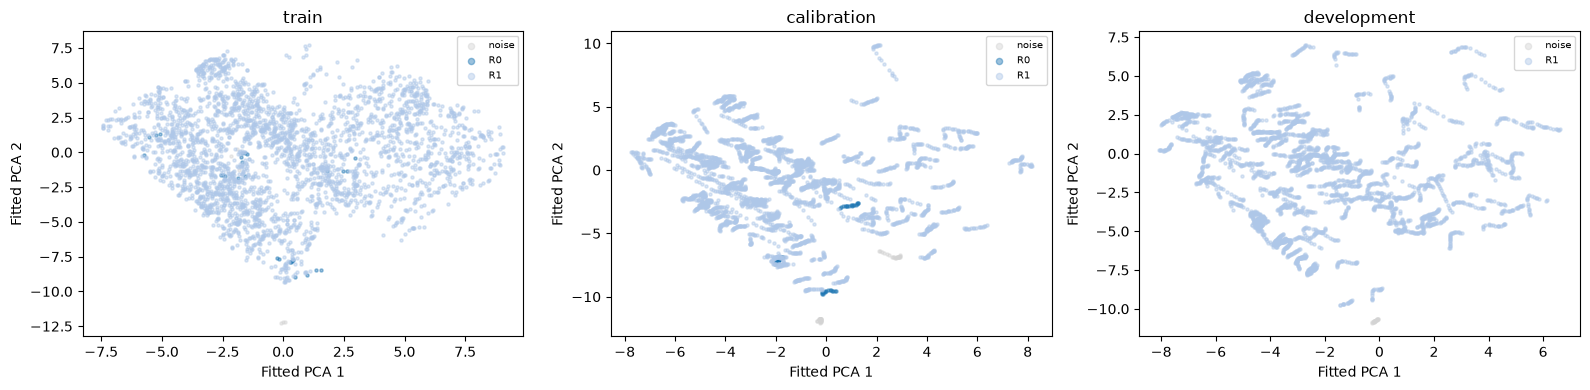

Provisional readiness checks:
positive_sampled_dbcv : True
multiple_supported_training_regimes : True
informative_stability_all_repeats : False
training_persistence_above_shuffle : True
Status: needs_review_before_combined_scoring
Inspect the failing checks and raw regime profiles. Do not open June or claim validated regimes.


In [11]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,split in zip(axes,['train','calibration','development']):
    indices=np.sort(np.random.default_rng(SEED).choice(len(Z[split]),min(3000,len(Z[split])),replace=False))
    labels=assignments[split]['regime_label'].to_numpy()[indices]
    for label in sorted(set(labels)):
        selected=labels==label
        ax.scatter(Z[split][indices[selected],0],Z[split][indices[selected],1],s=5,alpha=.45,
            color='lightgrey' if label<0 else plt.get_cmap('tab20')(int(label)%20),label='noise' if label<0 else f'R{label}')
    ax.set_title(split);ax.set_xlabel('Fitted PCA 1');ax.set_ylabel('Fitted PCA 2')
    if len(set(labels))<=12: ax.legend(fontsize=7,markerscale=2)
fig.tight_layout();fig.savefig(OUT/'regime_projection.png',dpi=180,bbox_inches='tight');plt.show()

train_support=profiles.loc[profiles['split'].eq('train') & profiles['regime_id'].ne('noise')]
train_lift=float(temporal_table.loc[temporal_table['split'].eq('train'),'persistence_lift'].iloc[0])
readiness={
    'positive_sampled_dbcv':bool(best['dbcv_sampled']>0),
    'multiple_supported_training_regimes':bool(len(train_support)>=2 and train_support['unique_drives'].ge(SETTINGS['minimum_unique_drives_per_regime']).all()),
    'informative_stability_all_repeats':bool(stability['ari_joint_assigned'].notna().all()
        and stability['ari_joint_assigned'].ge(SETTINGS['provisional_ari_target']).all()
        and stability['joint_assigned_fraction'].ge(.5).all()),
    'training_persistence_above_shuffle':bool(np.isfinite(train_lift) and train_lift>0),
}
ready=all(readiness.values())
print('Provisional readiness checks:')
for key,value in readiness.items():print(key,':',value)
print('Status:', 'supported_candidate_for_further_evaluation' if ready else 'needs_review_before_combined_scoring')
if not ready:
    print('Inspect the failing checks and raw regime profiles. Do not open June or claim validated regimes.')


## 12. Verify and record the completed discovery experiment
`regime_complete.json` records completion separately from readiness. A future combined-scoring notebook must inspect `provisional_ready` rather than assuming that a completion file proves scientific acceptance.

Report fitting sample size, retained PCA variance, candidate grid and sampled DBCV, noise fraction, regime drive support, age/temperature/counter profiles, persistence relative to shuffle, and resampling agreement. Record negative evidence. Later repeat across neural seeds and HDD models, and test the proposal's contamination quarantine/refinement before final claims.


In [12]:
pipeline_path=MODEL_DIR/'regime_pipeline.joblib'
reloaded=joblib.load(pipeline_path)  # Only load your own trusted model artifact.
check=Z['development'][:min(64,len(Z['development']))]
a,b=safe_predict(clusterer,check);c,d=safe_predict(reloaded['clusterer'],check)
np.testing.assert_array_equal(a,c);np.testing.assert_allclose(b,d)
for split,table in assignments.items():
    assert len(table)==len(metadata[split])
    assert table['membership_strength'].between(0,1).all()
    assert not table.duplicated(['serial_number','end_date']).any()
    assert np.isfinite(table['nearest_prototype_distance']).all()
record={'created_utc':datetime.now(timezone.utc).isoformat(),'run_id':RUN_ID,'ssl_id':SSL_ID,'regime_id':REGIME_ID,
    'analysis_complete':True,'provisional_ready':ready,'readiness_checks':readiness,
    'settings':SETTINGS,'selected_candidate':str(best['candidate']),
    'selected_min_cluster_size':int(best['min_cluster_size']),'selected_min_samples':int(best['min_samples']),
    'sampled_dbcv':float(best['dbcv_sampled']),'pca_retained_variance':float(pca.explained_variance_ratio_.sum()),
    'fit_windows':len(fit_indices),'fit_drives':int(fit_meta['serial_number'].nunique()),
    'failure_labels_used':False,'sealed_test_opened':False,
    'pipeline_sha256':sha256(pipeline_path),'encoder_complete_sha256':sha256(ENCODER_COMPLETE),
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'hdbscan':version('hdbscan')},
    'limitations':['one encoder seed and HDD model','thinned training fit subset','sampled DBCV estimate',
        'overlapping windows','conditional clustering stability, not neural-seed stability',
        'no validated healthy/failing semantics','no final anomaly calibration or drift policy',
        'quarantine/refinement and across-model evaluation still outstanding']}
(OUT/'regime_complete.json').write_text(json.dumps(record,indent=2))
print('NOTEBOOK 05 COMPLETE — regime discovery analysis saved.')
print('Provisional ready:',ready)
print('Results:',OUT)
print('Upload this notebook with saved outputs and Notebook 04 outputs for interpretation.')


NOTEBOOK 05 COMPLETE — regime discovery analysis saved.
Provisional ready: False
Results: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\results\single_model_q1q2_2021_v1\hdbscan_regimes_v1
Upload this notebook with saved outputs and Notebook 04 outputs for interpretation.


In [13]:
# Does not overwrite the original selected clustering pipeline.

STABILITY_OUT = OUT / "all_candidate_stability_v1"
STABILITY_OUT.mkdir(parents=True, exist_ok=True)

eligible_candidates = candidate_table.loc[
    candidate_table["eligible"]
].copy()

fit_serials = np.array(
    sorted(fit_meta["serial_number"].unique())
)

stability_details = []

for _, candidate in eligible_candidates.iterrows():
    name = candidate["candidate"]
    reference_model = fitted[name]

    reference_labels, _ = safe_predict(
        reference_model, anchor
    )

    for seed in SETTINGS["stability_seeds"]:
        sampled_ids = np.random.default_rng(seed).choice(
            fit_serials,
            size=max(
                2,
                int(
                    len(fit_serials)
                    * SETTINGS["stability_drive_fraction"]
                )
            ),
            replace=False
        )

        selected = fit_meta["serial_number"].isin(
            sampled_ids
        ).to_numpy()

        alternative = make_clusterer(
            candidate["min_cluster_size"],
            candidate["min_samples"]
        ).fit(Z_fit[selected])

        alternative_labels, _ = safe_predict(
            alternative, anchor
        )

        joint = (
            (reference_labels >= 0)
            & (alternative_labels >= 0)
        )

        informative = (
            joint.sum() >= 20
            and len(set(reference_labels[joint])) >= 2
            and len(set(alternative_labels[joint])) >= 2
        )

        ari = (
            adjusted_rand_score(
                reference_labels[joint],
                alternative_labels[joint]
            )
            if informative else np.nan
        )

        stability_details.append({
            "candidate": name,
            "seed": seed,
            "ari_joint_assigned": ari,
            "joint_assigned_fraction": joint.mean(),
            "passes_repeat": bool(
                informative
                and ari >= SETTINGS["provisional_ari_target"]
                and joint.mean() >= 0.50
            )
        })

details = pd.DataFrame(stability_details)

summary_rows = []

for name, group in details.groupby("candidate"):
    summary_rows.append({
        "candidate": name,
        "informative_repeats": int(
            group["ari_joint_assigned"].notna().sum()
        ),
        "minimum_ari": group["ari_joint_assigned"].min(),
        "median_ari": group["ari_joint_assigned"].median(),
        "minimum_joint_fraction":
            group["joint_assigned_fraction"].min(),
        "passes_all_repeats": bool(
            group["passes_repeat"].all()
        )
    })

stability_summary = pd.DataFrame(summary_rows).merge(
    eligible_candidates[
        ["candidate", "dbcv_sampled", "assigned_fraction"]
    ],
    on="candidate"
)

details.to_csv(
    STABILITY_OUT / "resampling_details.csv",
    index=False
)

stability_summary.to_csv(
    STABILITY_OUT / "candidate_stability_summary.csv",
    index=False
)

display(stability_summary)

,candidate,informative_repeats,minimum_ari,median_ari,minimum_joint_fraction,passes_all_repeats,dbcv_sampled,assigned_fraction
0,mcs30_ms15,2,0.900680,0.950340,0.3818,False,0.412651,0.865097
1,mcs30_ms5,2,1.000000,1.000000,0.9404,False,0.633990,0.996725
2,mcs60_ms15,1,1.000000,1.000000,0.3892,False,0.412651,0.865097
3,mcs60_ms5,2,0.875927,0.935714,0.4388,False,0.343917,0.894780


## Next research step
If the regime evidence is adequate, Notebook 06 combines reconstruction error, distance from accepted regimes and within-drive transition surprise, with calibration and synthetic checks. If not, first inspect encoder representations, preprocessing/age confounding, fit sampling and cluster stability under a newly recorded experiment version.

This notebook does not evaluate failure prediction, learn healthy labels, use June, or implement drift adaptation. No synthetic validation outputs supplied with this file are real research results.

**Official implementation references:**
- Frozen held-out assignments: https://hdbscan.readthedocs.io/en/latest/prediction_tutorial.html
- HDBSCAN parameters and DBCV API: https://hdbscan.readthedocs.io/en/latest/api.html

**Validation before delivery:** notebook schema and Python syntax plus synthetic execution, no-cluster handling, temporal gap handling, label invariance, saved-model reload and metadata alignment are checked. Real encoder embeddings were not attached, so full research results are generated only when you run this locally.
